# Coding Project 2: Credit Analytics

**Names of all group members:** Shangeeth Poobalasingam, Weifeng Ding

---

All requested quantities are printed or shown in tables/plots below. A concise *Project Report* is at the end of the notebook.

In [1]:
# Exercise 1.
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import log_loss

import warnings
warnings.filterwarnings('ignore', message='Setting penalty=None')
np.random.seed(0)  # for reproducibility
rng = np.random.default_rng(0)

m, n = 20000, 10000          # training / test sizes
N = m + n

# simulate explanatory variables (age, monthly income in CHF 1000, self-employed indicator), all independent
age = rng.uniform(18, 80, N)
income = rng.uniform(1, 15, N)
selfemp = (rng.uniform(0, 1, N) < 0.10).astype(float)   # 1 = self-employed (prob. 10%)
X = np.column_stack([age, income, selfemp])
X_train, X_test = X[:m], X[m:]

# a) empirical means and standard deviations over the TRAINING data (i = 1, ..., m)
mu_hat = X_train.mean(axis=0)
sigma_hat = X_train.std(axis=0)          # empirical std (ddof=0)
for name, mu, sd in zip(["age", "income (CHF 1000)", "self-employed"], mu_hat, sigma_hat):
    print(f"{name:18s} mean = {mu:8.4f}   std = {sd:8.4f}")
print("\n(theory: age 49 / 17.89, income 8 / 4.04, self-employed 0.1 / 0.3)")

# b) additional features (text answer):
# - Existing debt / debt-to-income ratio and credit history (past defaults, payment behaviour)
# - Loan characteristics: amount, duration and purpose of the loan
# - Household / stability information: marital status, number of dependents, home ownership vs. rent,
#   length of current employment / residence, education, sector of employment
# - Wealth/collateral: savings, assets

age                mean =  49.1618   std =  17.8365
income (CHF 1000)  mean =   8.0011   std =   4.0508
self-employed      mean =   0.1008   std =   0.3011

(theory: age 49 / 17.89, income 8 / 4.04, self-employed 0.1 / 0.3)


In [2]:
# Exercise 2.  Building the datasets
sigmoid = lambda z: 1. / (1. + np.exp(-z))

xi = rng.uniform(0, 1, N)   # the xi_i of the assignment

def p1(X):
    return sigmoid(13.3 - 0.33 * X[:, 0] + 3.5 * X[:, 1] - 3 * X[:, 2])

def p2(X):
    young_or_old = ((X[:, 0] < 25) | (X[:, 0] > 75)).astype(float)
    return sigmoid(5 - 10 * young_or_old + 1.1 * X[:, 1] - 1 * X[:, 2])

# y = 1 (good borrower) if xi <= p(x), else 0 (delinquent)
y1 = (xi <= p1(X)).astype(int)
y2 = (xi <= p2(X)).astype(int)

data = {1: dict(y_train=y1[:m], y_test=y1[m:]),
        2: dict(y_train=y2[:m], y_test=y2[m:])}
print("Share of good borrowers  data set 1: train %.3f, test %.3f" % (data[1]["y_train"].mean(), data[1]["y_test"].mean()))
print("Share of good borrowers  data set 2: train %.3f, test %.3f" % (data[2]["y_train"].mean(), data[2]["y_test"].mean()))

Share of good borrowers  data set 1: train 0.948, test 0.951
Share of good borrowers  data set 2: train 0.951, test 0.950


In [3]:
# Exercise 2. a)  Logistic regression + cross-entropy loss
# We use the unpenalised maximum-likelihood fit (C=np.inf), i.e. the plain logistic regression model of the lecture.
log_models = {}
print("Logistic regression: cross-entropy loss")
print("data set | train    | test")
for s in (1, 2):
    log_models[s] = LogisticRegression(C=np.inf, max_iter=10000).fit(X_train, data[s]["y_train"])
    tr = log_loss(data[s]["y_train"], log_models[s].predict_proba(X_train))
    te = log_loss(data[s]["y_test"],  log_models[s].predict_proba(X_test))
    print(f"   {s}     | {tr:.5f}  | {te:.5f}")
    print("         coefficients:", np.round(log_models[s].coef_[0], 3), " intercept:", np.round(log_models[s].intercept_[0], 3))

Logistic regression: cross-entropy loss
data set | train    | test
   1     | 0.03557  | 0.03409
         coefficients: [-0.32   3.286 -2.672]  intercept: 13.16
   2     | 0.14827  | 0.15140
         coefficients: [ 0.015  0.507 -0.206]  intercept: -0.338


In [4]:
# Exercise 2. b)  Normalised data: divide by the empirical std of the TRAINING data (for train and test)
Xn_train = X_train / sigma_hat
Xn_test  = X_test  / sigma_hat

In [5]:
# Exercise 2.b) (i) and (ii)  SVM with RBF kernel exp(-gamma ||x-x'||^2), gamma = 1/10,
# C = 1/(2*lambda*m) with lambda = 5/(2m)  ->  C = 1/5 = 0.2.   probability=True fits the Platt-scaling logistic on top.
lam = 5 / (2 * m)
C = 1 / (2 * lam * m)
print("C =", C)

svm_models = {}
for s in (1, 2):
    svm_models[s] = SVC(kernel='rbf', gamma=1/10, C=C, probability=True, random_state=0)
    svm_models[s].fit(Xn_train, data[s]["y_train"])
    print(f"data set {s}: SVM fitted, {svm_models[s].n_support_.sum()} support vectors")

C = 0.2
data set 1: SVM fitted, 1448 support vectors
data set 2: SVM fitted, 1935 support vectors


In [6]:
# Exercise 2.b (iii)  Cross-entropy loss of the SVM-based probabilities on the normalised data
print("SVM (+Platt scaling): cross-entropy loss")
print("data set | train    | test")
for s in (1, 2):
    tr = log_loss(data[s]["y_train"], svm_models[s].predict_proba(Xn_train))
    te = log_loss(data[s]["y_test"],  svm_models[s].predict_proba(Xn_test))
    print(f"   {s}     | {tr:.5f}  | {te:.5f}")

# for reference: the loss of the TRUE conditional probabilities on the test data (the best achievable in expectation)
print("\nReference: cross-entropy of the true p_s on the test data:",
      {s: round(log_loss(data[s]["y_test"], np.column_stack([1-f(X_test), f(X_test)])), 5) for s, f in ((1, p1), (2, p2))})

SVM (+Platt scaling): cross-entropy loss
data set | train    | test
   1     | 0.03782  | 0.03667
   2     | 0.06420  | 0.07410

Reference: cross-entropy of the true p_s on the test data: {1: 0.03411, 2: 0.04396}


In [7]:
# Exercise 2.b (iv)
# Standardising means subtracting the training means mu_j from each feature, i.e. a pure translation x -> x - mu.
# The RBF kernel k(x,x') = exp(-gamma ||x-x'||^2) only depends on the differences x - x', which are unchanged by a common
# translation. Hence the kernel (Gram) matrix, the SVM optimisation problem, f_svm (up to the same shift) and the
# Platt-scaled probabilities are identical, and the losses would not change (apart from tiny numerical differences).
# Verification (cheap check on data set 2):
sc_train = (X_train - mu_hat) / sigma_hat
sc_test  = (X_test  - mu_hat) / sigma_hat
chk = SVC(kernel='rbf', gamma=1/10, C=C, probability=True, random_state=0).fit(sc_train, data[2]["y_train"])
print("test loss with standardised data (data set 2): %.5f  vs normalised: %.5f" % (
      log_loss(data[2]["y_test"], chk.predict_proba(sc_test)),
      log_loss(data[2]["y_test"], svm_models[2].predict_proba(Xn_test))))

test loss with standardised data (data set 2): 0.07410  vs normalised: 0.07410


AUC (area under the FDR-TPR curve, LOWER is better):
data set | logistic | SVM
   1     | 0.000203 | 0.000236
   2     | 0.008026 | 0.001038
TPR range covered: {('log', 1): (0.0001, 1.0), ('log', 2): (0.0001, 1.0), ('svm', 1): (0.0001, 1.0), ('svm', 2): (0.0001, 1.0)}


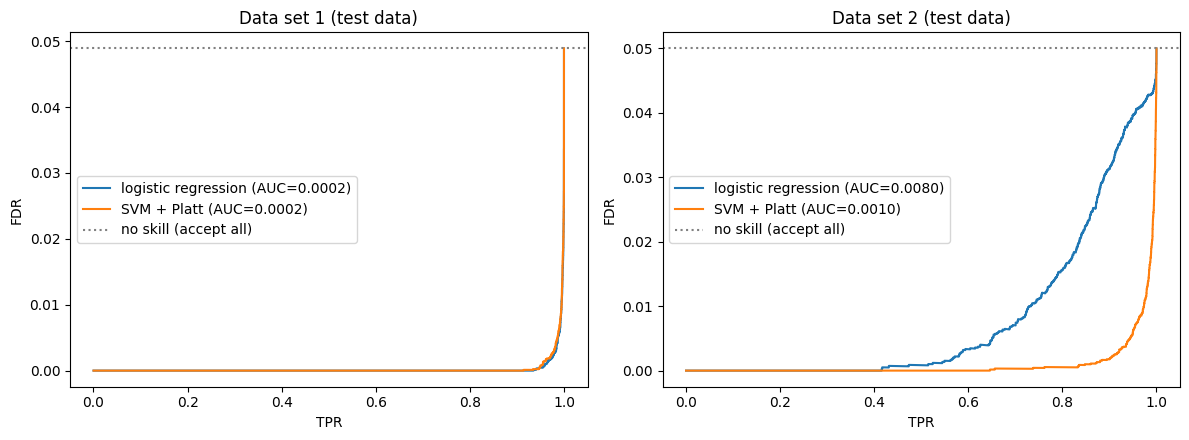

In [8]:
# Exercise 2.c  FDR/TPR-curves and AUC on the test data
def fdr_tpr_curve(y, p, tiebreak=None):
    """TPR/FDR for the rule 'accept (predict 1) if p >= c' for all thresholds c = predicted probabilities.
    Predicted probabilities that are identical (e.g. exactly 1.0 after floating-point saturation or clipping) are ties;
    if a secondary score `tiebreak` is given it is used to order such ties, which refines the curve inside tie groups."""
    tb = np.zeros_like(p) if tiebreak is None else tiebreak
    order = np.lexsort((-tb, -p))             # sort by p descending, ties by secondary score descending
    ps, ts, ys = p[order], tb[order], y[order]
    tp = np.cumsum(ys)                        # true positives when accepting the first j applicants
    fp = np.cumsum(1 - ys)                    # false positives
    last = np.r_[(ps[1:] != ps[:-1]) | (ts[1:] != ts[:-1]), True]   # one point per distinct threshold
    tp, fp = tp[last], fp[last]
    P = ys.sum()                              # number of positives (depends only on the data set)
    return tp / P, fp / (tp + fp)             # TPR (increasing), FDR

def riemann_auc(a, b):
    """sum_i (b_i + b_{i+1})/2 * (a_{i+1} - a_i), a sorted increasingly."""
    return np.sum((b[:-1] + b[1:]) / 2 * np.diff(a))

probs_test = {("log", s): log_models[s].predict_proba(X_test)[:, 1] for s in (1, 2)}
probs_test.update({("svm", s): svm_models[s].predict_proba(Xn_test)[:, 1] for s in (1, 2)})

# Secondary scores used only to break exact ties in p_hat (for very confident predictions p_hat is 1.0 up to rounding)
scores = {("log", s): log_models[s].decision_function(X_test) for s in (1, 2)}
scores.update({("svm", s): svm_models[s].decision_function(Xn_test) for s in (1, 2)})

curves, auc = {}, {}
for key, p in probs_test.items():
    mod, s = key
    curves[key] = fdr_tpr_curve(data[s]["y_test"], p, scores[key])
    auc[(mod, s)] = riemann_auc(*curves[(mod, s)])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, s in zip(axes, (1, 2)):
    for mod, lab in (("log", "logistic regression"), ("svm", "SVM + Platt")):
        tpr, fdr = curves[(mod, s)]
        ax.plot(tpr, fdr, label=f"{lab} (AUC={auc[(mod, s)]:.4f})")
    ax.axhline(1 - data[s]["y_test"].mean(), color="gray", ls=":", label="no skill (accept all)")
    ax.set_xlabel("TPR"); ax.set_ylabel("FDR"); ax.set_title(f"Data set {s} (test data)"); ax.legend()
plt.tight_layout(); plt.show()

print("AUC (area under the FDR-TPR curve, LOWER is better):")
print("data set | logistic | SVM")
for s in (1, 2):
    print(f"   {s}     | {auc[('log', s)]:.6f} | {auc[('svm', s)]:.6f}")
print("TPR range covered:", {k: (round(float(v[0][0]), 4), round(float(v[0][-1]), 4)) for k, v in curves.items()})

**Construction and interpretation (Ex. 2c).** For a threshold $c$ we accept (predict $y=1$, i.e. "good borrower") every test applicant with predicted repayment probability $\hat p\ge c$. Then $\mathrm{TPR}(c)=TP/P$ (share of all good borrowers that we accept) and $\mathrm{FDR}(c)=FP/(TP+FP)$ (share of delinquent borrowers among the accepted loans). Sorting the test applicants by $\hat p$ and taking cumulative sums gives the exact curve over all distinct thresholds (ties in $\hat p$, which occur for very confident predictions, are ordered by the raw model score), and the curve covers TPR from about $0$ to $1$. The AUC is the Riemann (trapezoidal) area under FDR as a function of TPR.

Because FDR is on the vertical axis, **a smaller AUC is better**: it means that, averaged over the acceptance volume, a smaller fraction of accepted loans default. An uninformative score would give a flat curve at $1-$(share of good borrowers), which is the dotted line.

**Comparison.** On data set 1 (the true $p_1$ is exactly a logistic model) both classifiers are practically equivalent (AUC $\approx 2\cdot10^{-4}$, the logistic model marginally better, and a test loss of 0.034 vs 0.037): the correctly specified, simpler model is as good as the flexible one. On data set 2 the true log-odds is not monotone in age (a penalty of $-10$ below 25 and above 75). A logistic regression can only fit a linear effect of age (the fitted coefficient is $\approx 0$), so it cannot rank young/old applicants as risky and its FDR is much higher for a given TPR (AUC 0.0080 vs 0.0010 for the SVM; test loss 0.151 vs 0.074). The RBF-SVM learns the non-linear age effect and is clearly better.

In [9]:
# Exercise 3.  Lending strategies on data set 2 (test data)
# Market scenarios: D[i,k] = 1{xi_{i,k} <= p2(x_{m+i})}, n x 50000.  D (5e8 entries) is generated in column blocks and
# every block is immediately used to compute the profits of all three strategies in these scenarios (the same scenarios
# are used for all strategies, which makes the comparison fair and avoids storing D).
K, B = 50000, 2500
p2_test = p2(X_test)

# selection vectors and interest rates
sel = {
    "(i) all, 5.5%":        (np.ones(n, dtype=bool), 0.055),
    "(ii) logistic>=95%, 1%": (probs_test[("log", 2)] >= 0.95, 0.01),
    "(iii) SVM>=95%, 1%":     (probs_test[("svm", 2)] >= 0.95, 0.01),
}
loan = 1000.0
# profit in scenario k = sum_i sel_i * ( loan*(1+r)*D_ik - loan ): repaid -> +r*loan, default -> -loan
W = np.column_stack([s.astype(float) * loan * (1 + r) for s, r in sel.values()])       # n x 3 weights
const = np.array([s.sum() * loan for s, r in sel.values()])                              # invested capital

rng_D = np.random.default_rng(12345)
PL = np.empty((K, 3))
for start in range(0, K, B):
    D = (rng_D.uniform(size=(n, B)) <= p2_test[:, None]).astype(float)   # block of columns of D
    PL[start:start + B] = D.T @ W - const
    del D

for j, (name, (s, r)) in enumerate(sel.items()):
    print(f"{name:24s}: {s.sum():5d} loans granted, capital {s.sum()*loan:10.0f} CHF")

(i) all, 5.5%           : 10000 loans granted, capital   10000000 CHF
(ii) logistic>=95%, 1%  :  7145 loans granted, capital    7145000 CHF
(iii) SVM>=95%, 1%      :  8829 loans granted, capital    8829000 CHF


strategy                     E[P&L] (CHF)   95%-VaR (CHF)   std (CHF)  E[P&L]/capital
(i) all, 5.5%                      10,344           9,150      11,930         0.1034%
(ii) logistic>=95%, 1%              1,239          10,360       7,090         0.0173%
(iii) SVM>=95%, 1%                 62,422         -53,950       4,703         0.7070%

Exact expected P&L (from p2): {'(i) all, 5.5%': 10252, '(ii) logistic>=95%, 1%': 1197, '(iii) SVM>=95%, 1%': 62410}
Monte Carlo standard error of E[P&L]: {'(i) all, 5.5%': 53.4, '(ii) logistic>=95%, 1%': 31.7, '(iii) SVM>=95%, 1%': 21.0}
True average default probability of granted loans: {'(i) all, 5.5%': 0.0512, '(ii) logistic>=95%, 1%': 0.0097, '(iii) SVM>=95%, 1%': 0.0029}


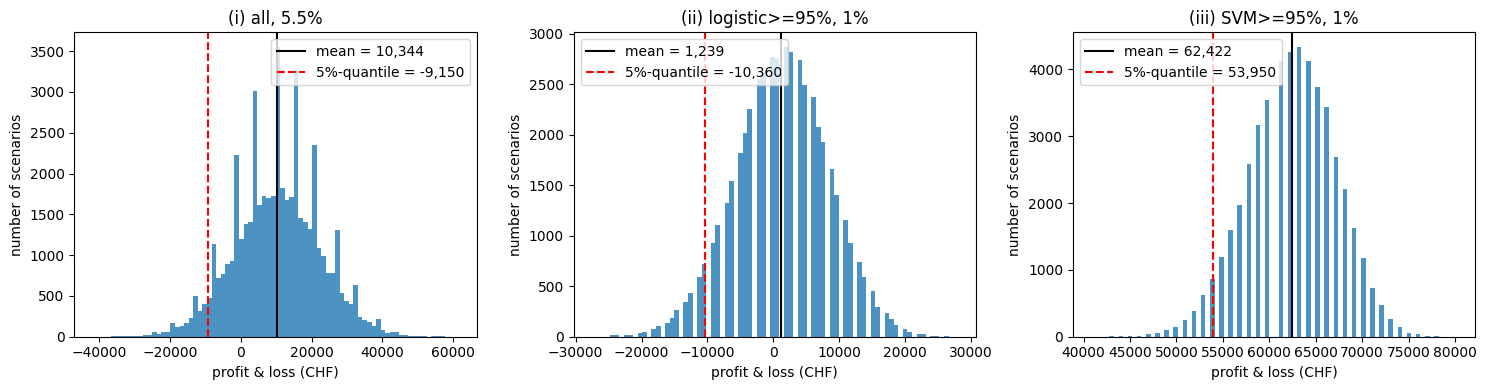

In [10]:
# a) histograms of profits & losses, expected P&L;  b) 95%-VaR = - 5%-quantile
results = {}
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for j, (ax, name) in enumerate(zip(axes, sel)):
    pl = PL[:, j]
    ev, var95 = pl.mean(), -np.quantile(pl, 0.05)
    results[name] = (ev, var95, pl.std())
    ax.hist(pl, bins=80, color="tab:blue", alpha=.8)
    ax.axvline(ev, color="k", label=f"mean = {ev:,.0f}")
    ax.axvline(-var95, color="r", ls="--", label=f"5%-quantile = {-var95:,.0f}")
    ax.set_title(name); ax.set_xlabel("profit & loss (CHF)"); ax.set_ylabel("number of scenarios"); ax.legend()
plt.tight_layout(); plt.show()

print(f"{'strategy':26s} {'E[P&L] (CHF)':>14s} {'95%-VaR (CHF)':>15s} {'std (CHF)':>11s}  {'E[P&L]/capital':>14s}")
for j, (name, (ev, var95, sd)) in enumerate(results.items()):
    cap = sel[name][0].sum() * loan
    print(f"{name:26s} {ev:14,.0f} {var95:15,.0f} {sd:11,.0f}  {ev/cap:14.4%}")

# sanity check: exact expected P&L from the true probabilities p2
print("\nExact expected P&L (from p2):", {name: round(float(np.sum(s * (loan*(1+r)*p2_test - loan))))
                                      for name, (s, r) in sel.items()})
# how reliable is the Monte Carlo estimate of the expectation?  (standard error)
print("Monte Carlo standard error of E[P&L]:", {name: round(float(res[2] / np.sqrt(K)), 1) for name, res in results.items()})
# true default rate among granted loans
print("True average default probability of granted loans:", {name: round(float(1 - p2_test[s].mean()), 4) for name, (s, r) in sel.items()})

**Comparison of strategies (Ex. 3c).**

* **(i) Lend to everybody at 5.5%.** About 5% of all loans default, and the interest (5.5%) only barely compensates for this: the expected profit is only about CHF 10,300 on CHF 10 million lent (0.1%), with a large spread (std $\approx$ CHF 11,900), and the 95%-VaR is about CHF 9,200 (a loss of this size or worse occurs with probability 5%).
* **(ii) Logistic selection at 1%.** The logistic model of data set 2 cannot represent the high default risk of very young / old applicants, so the 95%-threshold removes applicants mostly according to income and employment status. The granted loans still default with a probability of about 1% (true value 0.97%), which equals the interest charged; the expected profit is close to zero (about CHF 1,200) and the 95%-VaR (about CHF 10,400) is even worse than for (i). The selection cuts the volume (7,145 loans) without improving the quality enough to pay for the lower interest rate.
* **(iii) SVM selection at 1%.** The SVM identifies the risky age groups and the weak-income applicants. The 8,829 granted loans have a true default probability of only about 0.3%, so the 1% interest yields an expected profit of about CHF 62,400 (about 0.7% on the invested capital, six times that of (i)), with the smallest standard deviation (CHF 4,700). The negative VaR of about $-$CHF 54,000 means that even the 5%-quantile of the profit is positive: in 95% of the scenarios the strategy makes more than CHF 54,000.

Hence (iii) $\gg$ (i) $>$ (ii) in terms of expected profit and (iii) is also the best in terms of risk. The better classifier (data set 2: lower loss, lower AUC) translates directly into a better lending strategy; a threshold on a misspecified model is not necessarily better than lending to everybody.

## Project Report

### Approach
We simulated $m+n=30{,}000$ applicants (age and monthly income uniform, 10% self-employed, independent; $m=20{,}000$ training, $n=10{,}000$ test) and two artificial repayment data sets with true repayment probabilities $p_1$ (logistic-linear) and $p_2$ (non-monotone in age: strongly penalised below 25 and above 75). On both data sets we fitted an (unpenalised) logistic regression on the raw features and an RBF-SVM ($\gamma=1/10$, $C=0.2$, Platt scaling) on features divided by the training standard deviations. The classifiers were compared on the test data by the cross-entropy loss and by FDR/TPR-curves with their AUC. For data set 2 we then compared three lending strategies (lend to all at 5.5%, select with logistic regression resp. SVM using $\hat p\ge 95\%$ and charge 1%) by simulating 50,000 common market scenarios $D$ (generated blockwise to save memory) and computing the expected profit and the 95%-VaR.

### Model selection
For the lending decision we would rely on the **SVM** (with Platt scaling). On data set 1 logistic regression and SVM are equally good, and logistic regression is preferable for simplicity and interpretability because it is correctly specified there. On data set 2, where the true risk is non-monotone in age, logistic regression is misspecified and the SVM is clearly better (loss and AUC, see below), and this is what matters for the lending strategy. Since the true model is unknown in practice, a flexible model that is not worse when the simple model is right is the safer choice (this should be backed up by validation/hyperparameter tuning on real data).

### Key results
| | data set 1 | data set 2 |
|---|---|---|
| test cross-entropy, logistic / SVM | 0.0341 / 0.0367 | 0.1514 / 0.0741 |
| (true $p$: 0.0341) | | (true $p$: 0.0440) |
| AUC (FDR-TPR, lower is better), logistic / SVM | 0.000203 / 0.000236 | 0.008026 / 0.001038 |

| strategy (data set 2) | loans | E[P&L] (CHF) | 95%-VaR (CHF) |
|---|---|---|---|
| (i) all, 5.5% | 10,000 | ~10,300 | ~9,150 |
| (ii) logistic $\ge$95%, 1% | 7,145 | ~1,200 | ~10,400 |
| (iii) SVM $\ge$95%, 1% | 8,829 | ~62,400 | ~$-$54,000 (profit positive in 95% of scenarios) |

(Exact numbers are in the printed output above.)

### Interpretation
Model quality is only partly visible in the loss on data set 1, where both models are essentially at the Bayes loss; it matters a lot on data set 2, where the logistic model cannot capture the age effect (fitted age coefficient $\approx 0$) and gets about twice the loss of the SVM. Ranking quality (AUC) translates directly into money: the SVM-based strategy selects applicants whose true default rate is about 0.3% (instead of 1% for the logistic selection and 5% for the whole population) and therefore earns six times the expected profit of the naive strategy at a lower risk. A cheap-money strategy (1% interest) only works if the selection is very accurate; with a misspecified model it is worse than charging a high rate to everybody.

### Robustness
The conclusions are subject to two sources of randomness. (1) The simulated data: with $m=20{,}000$ training points the fitted models and the test losses vary little, but the delinquent borrowers are only 5% of the data (about 500 test defaults), so the AUC values and the chosen set of applicants in (ii)/(iii) fluctuate; the AUC difference on data set 1 (2.0 vs 2.4$\cdot10^{-4}$) is tiny and should not be over-interpreted, whereas the large gaps on data set 2 are unlikely to be due to noise. (2) The market scenarios: with 50,000 scenarios the Monte Carlo standard error of the expected profit is only about CHF 20-50 (checked against the exact expectation computed from $p_2$), so the ranking of the strategies is not affected. The VaR (a 5% quantile) is noisier than the mean but still precise relative to the differences between strategies. Note that the scenarios are conditional on a single test set, i.e. the variability coming from the realised test sample is not captured by the scenarios, and the ranking of (i) and (ii) in particular could change with another seed. We did not repeat the experiment with other seeds.

### Limitations
The data are synthetic, with only three independent features and known functional forms, which is much simpler than real credit data (many correlated features, missing data, selection bias since defaults are only observed for accepted applicants). The loan outcomes are binary (no partial recovery, no prepayment, no variation in loan size or maturity), defaults are independent given the features (no systematic risk or economic cycle, which would fatten the tails of the P&L and make VaR much larger than here), and interest rates are fixed instead of risk-based. The selection threshold of 95% was fixed and not optimised, the SVM hyperparameters were given and not tuned, and Platt-scaled SVM probabilities are less well calibrated than those of a correctly specified logistic model. The strategies ignore costs of capital and operational costs, and the P&L is evaluated on the same test applicants that are used for the selection (in a single period).